C_J de referencia = 2.982607579252
Integrando órbita para velocidad vertical 𝓏̇₀ = 0.01
Integrando órbita para velocidad vertical 𝓏̇₀ = 0.046022
Integrando órbita para velocidad vertical 𝓏̇₀ = 0.06
Integrando órbita para velocidad vertical 𝓏̇₀ = 0.08
Integrando órbita para velocidad vertical 𝓏̇₀ = 0.1
Integrando órbita para velocidad vertical 𝓏̇₀ = 0.15
Integrando órbita para velocidad vertical 𝓏̇₀ = 0.5

¡Figura guardada con éxito en: secciones_poincare\matriz_canonica_secciones_poincare.png!


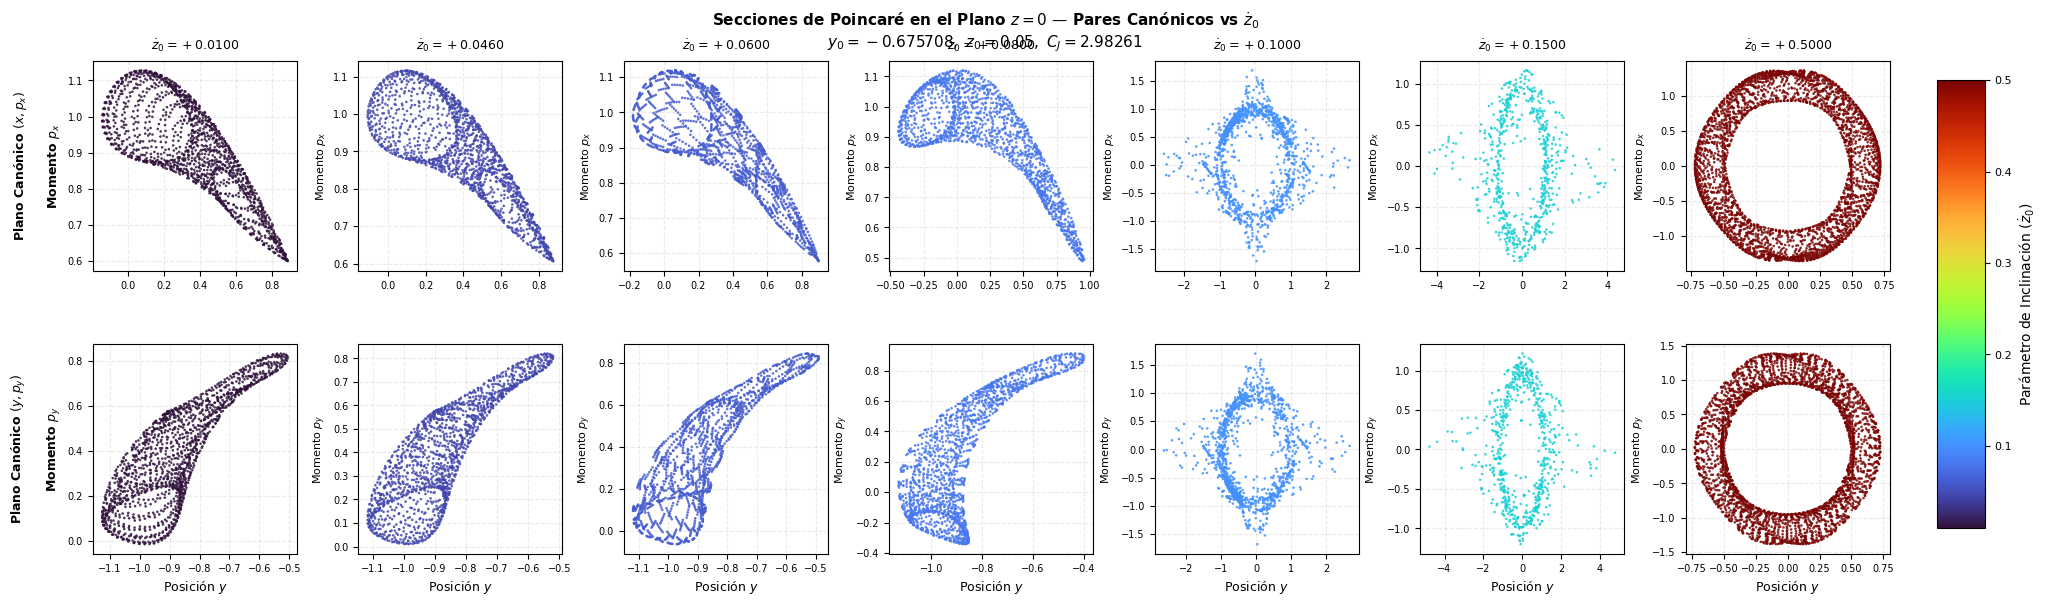

Proceso finalizado correctamente.


In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
import os

if not os.environ.get("DISPLAY") and os.name != "nt":
    matplotlib.use("Agg")

# ============================================================
# 1. PARÁMETROS GENERALES
# ============================================================

MU = 9.5372e-4

# ---- Lo que se FIJA ----
Y0_FIXED = -0.675708      # Posición y inicial (fija)
VX0 = 0.168444            # Velocidad x inicial (fija)
VY0 = 0.185260            # Velocidad y inicial (fija)
Z0_FIXED = 0.05           # Posición z inicial fija para esta matriz

# ---- Lo que VARÍA por columna (\dot{z}_0) ----
ZDOT0_VALS = [0.01, 0.046022, 0.06, 0.08, 0.1, 0.15, 0.5]

# ---- FILAS: Pares Canónicos del plano de sección z = 0 ----
# Estructura: (Etiqueta Eje X, Etiqueta Eje Y, Título de Fila, índice_x_en_all_pts, índice_y_en_all_pts)
CANONICAL_PAIRS = [
    (r"Posición $x$", r"Momento $p_x$", "Plano Canónico $(x, p_x)$", 0, 1),
    (r"Posición $y$", r"Momento $p_y$", "Plano Canónico $(y, p_y)$", 2, 3)
]

# ---- Referencia para elegir rama de x0 ----
X_REF = 0.563059          

# ---- Rango de búsqueda de x0 ----
X_SEARCH_MIN = -0.5
X_SEARCH_MAX =  1.5

# ---- Integración ----
T_MAX = 5000
RTOL = 1e-10
ATOL = 1e-12
MAX_STEP = 0.2
MAX_POINTS = 2500

OUTPUT_DIR = "secciones_poincare"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# 2. CONSTANTE DE JACOBI DE REFERENCIA NASA
# ============================================================

X_NASA = 0.525558
Y_NASA = 0.911946
Z_NASA = -0.041771
VX_NASA = 0.038913
VY_NASA = -0.152654
VZ_NASA = -0.004500


def jacobi_from_velocity(x, y, z, vx, vy, vz):
    r1 = np.sqrt((x + MU)**2 + y**2 + z**2)
    r2 = np.sqrt((x - 1 + MU)**2 + y**2 + z**2)
    return (
        x**2 + y**2 + z**2
        + 2*(1 - MU)/r1
        + 2*MU/r2
        - vx**2 - vy**2 - vz**2
    )


CJ_REF = jacobi_from_velocity(
    X_NASA, Y_NASA, Z_NASA,
    VX_NASA, VY_NASA, VZ_NASA
)

print(f"C_J de referencia = {CJ_REF:.12f}")


# ============================================================
# 3. RESOLVER x0 POR JACOBI
# ============================================================

def jacobi_of_x(x, y, z, vx, vy, vz):
    return jacobi_from_velocity(x, y, z, vx, vy, vz) - CJ_REF


def solve_x0(y, z, vx, vy, vz,
             x_min=X_SEARCH_MIN,
             x_max=X_SEARCH_MAX,
             x_ref=X_REF,
             n_scan=400):
    
    xs = np.linspace(x_min, x_max, n_scan)
    fs = np.array([jacobi_of_x(x, y, z, vx, vy, vz) for x in xs])

    roots = []
    for k in range(len(xs) - 1):
        f0, f1 = fs[k], fs[k+1]
        if not np.isfinite(f0) or not np.isfinite(f1):
            continue
        if f0 == 0.0:
            roots.append(xs[k])
            continue
        if f0 * f1 < 0.0:
            try:
                r = brentq(
                    lambda xx: jacobi_of_x(xx, y, z, vx, vy, vz),
                    xs[k], xs[k+1],
                    xtol=1e-13, rtol=1e-13, maxiter=200
                )
                roots.append(r)
            except ValueError:
                continue

    roots_unique = []
    for r in roots:
        if not any(abs(r - q) < 1e-8 for q in roots_unique):
            roots_unique.append(r)

    if not roots_unique:
        raise ValueError(f"Sin raíz real para z={z}, zdot={vz}")

    x_sol = min(roots_unique, key=lambda r: abs(r - x_ref))
    return x_sol, len(roots_unique), roots_unique


# ============================================================
# 4. CONDICIONES INICIALES
# ============================================================

def initial_state(zdot0):
    x0, n_roots, all_roots = solve_x0(
        y=Y0_FIXED, z=Z0_FIXED,
        vx=VX0, vy=VY0, vz=zdot0
    )

    px = VX0 - Y0_FIXED
    py = VY0 + x0
    pz = zdot0

    S0 = np.array([x0, Y0_FIXED, Z0_FIXED, px, py, pz])
    return S0, x0, n_roots, all_roots


# ============================================================
# 5. ECUACIONES DE HAMILTON
# ============================================================

def hamilton_rhs(t, S):
    x, y, z, px, py, pz = S

    r1 = np.sqrt((x + MU)**2 + y**2 + z**2)
    r2 = np.sqrt((x - 1 + MU)**2 + y**2 + z**2)

    a1 = (1 - MU) / r1**3
    a2 = MU / r2**3

    dx = px + y
    dy = py - x
    dz = pz

    dpx = py - a1*(x + MU) - a2*(x - 1 + MU)
    dpy = -px - (a1 + a2)*y
    dpz = -(a1 + a2)*z

    return [dx, dy, dz, dpx, dpy, dpz]


# ============================================================
# 6. SECCIÓN DE POINCARE: z = 0
# ============================================================

def event_z(t, S):
    return S[2]

event_z.terminal = False
event_z.direction = 0


# ============================================================
# 7. INTEGRACIÓN DE UNA ÓRBITA
# ============================================================

def integrate_orbit(zdot0):
    S0, x0, n_roots, all_roots = initial_state(zdot0)

    sol = solve_ivp(
        hamilton_rhs,
        (0, T_MAX),
        S0,
        method="DOP853",
        events=event_z,
        rtol=RTOL,
        atol=ATOL,
        max_step=MAX_STEP
    )

    states = sol.y_events[0]
    times = sol.t_events[0]

    valid = times > 1e-8
    states = states[valid]

    n_total = len(states)
    
    # Extraemos explícitamente los 4 elementos del espacio fase en el corte:
    # Estados devueltos por solve_ivp: [x, y, z, px, py, pz]
    # Columnas correspondientes:
    # 0 -> x
    # 3 -> px
    # 1 -> y
    # 4 -> py
    all_pts = states[:, [0, 3, 1, 4]]

    return {
        "zdot0": zdot0,
        "x0": x0,
        "n_roots": n_roots,
        "points_all": all_pts,
        "success": sol.success,
        "n_total": n_total,
    }


# ============================================================
# 8. CONFIGURACIÓN DE LA MATRIZ DE GRÁFICAS
# ============================================================

n_rows = len(CANONICAL_PAIRS)
n_cols = len(ZDOT0_VALS)

# IMPORTANTE: Eliminamos sharex y sharey globales para evitar conflictos de escala entre filas diferentes
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(3.4 * n_cols, 3.2 * n_rows),
    squeeze=False
)

norm = Normalize(vmin=min(ZDOT0_VALS), vmax=max(ZDOT0_VALS))
cmap = plt.cm.turbo

results_cache = {}

# Pre-calculamos las integraciones por cada valor de \dot{z}_0 (columnas)
for j, zdot0 in enumerate(ZDOT0_VALS):
    print(f"Integrando órbita para velocidad vertical 𝓏̇₀ = {zdot0}")
    try:
        results_cache[zdot0] = integrate_orbit(zdot0)
    except ValueError as e:
        print(f"  AVISO: {e}")
        results_cache[zdot0] = None

# Rellenamos la matriz de subgráficos
for i, (xlab, ylab, row_title, idx_x, idx_y) in enumerate(CANONICAL_PAIRS):
    for j, zdot0 in enumerate(ZDOT0_VALS):
        ax = axes[i, j]
        res = results_cache[zdot0]
        color = cmap(norm(zdot0))

        if res is None or not res["success"] or res["n_total"] == 0:
            ax.text(
                0.5, 0.5,
                "Sin convergencia",
                ha="center", va="center",
                transform=ax.transAxes,
                fontsize=7, color="crimson", style="italic"
            )
            ax.grid(alpha=0.25, linestyle="--")
            continue

        pts = res["points_all"]
        x_vals = pts[:, idx_x]
        y_vals = pts[:, idx_y]

        ax.scatter(x_vals, y_vals, s=3.5, color=color, alpha=0.85, edgecolors="none")

        ax.grid(alpha=0.25, linestyle="--")
        ax.tick_params(labelsize=7)

        # Etiquetas de los ejes verticales (izquierda de cada fila)
        if j == 0:
            ax.set_ylabel(f"{row_title}\n\n{ylab}", fontsize=9, fontweight="bold")
        else:
            ax.set_ylabel(ylab, fontsize=8)

        # Títulos de columnas en la primera fila (valores de \dot{z}_0)
        if i == 0:
            ax.set_title(rf"$\dot{{z}}_0 = {zdot0:+.4f}$", fontsize=9, fontweight="bold", pad=8)

        # Etiquetas de los ejes horizontales (abajo de cada columna)
        if i == n_rows - 1:
            ax.set_xlabel(xlab, fontsize=9)


# ============================================================
# 9. TÍTULO GLOBAL Y BARRA DE COLOR
# ============================================================

fig.subplots_adjust(right=0.88, hspace=0.35, wspace=0.3)

cax = fig.add_axes([0.90, 0.15, 0.02, 0.70])
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(r"Parámetro de Inclinación ($\dot{z}_0$)", fontsize=10)
cbar.ax.tick_params(labelsize=8)

fig.suptitle(
    r"Secciones de Poincaré en el Plano $z = 0$ — Pares Canónicos vs $\dot{z}_0$" + "\n" +
    rf"$y_0 = {Y0_FIXED},\ z_0 = {Z0_FIXED},\ C_J = {CJ_REF:.5f}$",
    fontsize=11, fontweight="bold", y=0.96
)

filename = os.path.join(OUTPUT_DIR, "matriz_canonica_secciones_poincare.png")
fig.savefig(filename, dpi=180, bbox_inches="tight")
print(f"\n¡Figura guardada con éxito en: {filename}!")

if matplotlib.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)

print("Proceso finalizado correctamente.")